<a href="https://colab.research.google.com/github/carlavilla/DataManagement/blob/main/Flooding_and_Housing_NJ.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import time, os, sys, re
import zipfile, json, datetime, string
import numpy as np
from statistics import *

import matplotlib.pyplot as plt
import seaborn as sns

import pandas as pd
import pandas_datareader as pdr
from pandas_datareader import wb
from pandas.io.formats.style import Styler

import missingno as msno

from google.colab import files
from google.colab import data_table
data_table.enable_dataframe_formatter()
data_table.max_columns = 50
#!and may have to click at top right spreadsheet icon

from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"

#ALICE Data

Uses data from the ACS to report the number of households living in poverty as well as those in financial hardship. ALICE scores take into consideration household costs (e.g. housing, food, transportation, healthcare, technology) based on the location. Households under the ALICE threshold do not have enough income to afford their basic needs. </br>

**Variables of interest:** Per county, total number of households, households in poverty, ALICE households, ALICE income thresholds for households under 65, ALICE income thresholds for households over 65.</br>

**Timeframe available:** 2010, 2012, 2014, 2016, 2018, 2019, 2021, 2022, 2023, 2024. </br>

**Areas in dataset:** Counties in New Jersey. </br>

*Thresholds are for the average household, calculated by dividing the total number of households in each county by the population in that age group in that county.

**Source:** [United for Alice 2026 Report](https://www.unitedforalice.org/county-reports/new-jersey)

In [2]:
! wget -q -O ALICE_NJ.xlsx https://raw.githubusercontent.com/carlavilla/DataManagement/main/ALICE_NJ.xlsx
alice=pd.read_excel('ALICE_NJ.xlsx', sheet_name= "County")
alice.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 210 entries, 0 to 209
Data columns (total 13 columns):
 #   Column                                  Non-Null Count  Dtype 
---  ------                                  --------------  ----- 
 0   State                                   210 non-null    object
 1   Year                                    210 non-null    int64 
 2   GEO.id2                                 210 non-null    int64 
 3   GEO.display_label                       210 non-null    object
 4   County                                  210 non-null    object
 5   State Abbr                              210 non-null    object
 6   Households                              210 non-null    int64 
 7   Poverty Households                      210 non-null    int64 
 8   ALICE Households                        210 non-null    int64 
 9   Above ALICE Households                  210 non-null    int64 
 10  ALICE Threshold - HH under 65           210 non-null    int64 
 11  ALICE 

In [3]:
alice.head()

,State,Year,GEO.id2,GEO.display_label,County,State Abbr,Households,Poverty Households,ALICE Households,Above ALICE Households,ALICE Threshold - HH under 65,ALICE Threshold - HH 65 years and over,Source: American Community Survey
0,New Jersey,2010,34001,"Atlantic County, New Jersey",Atlantic,NJ\n\n,100096,12106,30689,57301,45000,40000,1-Year
1,New Jersey,2012,34001,"Atlantic County, New Jersey",Atlantic,NJ\n\n,100065,13381,32214,54470,50000,40000,1-Year
2,New Jersey,2014,34001,"Atlantic County, New Jersey",Atlantic,NJ\n\n,101937,14493,30462,56982,50000,45000,1-Year
3,New Jersey,2016,34001,"Atlantic County, New Jersey",Atlantic,NJ,96777,13436,32971,50370,60000,45000,1-Year
4,New Jersey,2018,34001,"Atlantic County, New Jersey",Atlantic,NJ\n\n,96981,12343,31914,52724,60000,50000,1-Year


In [4]:
alice = alice.drop(columns=["State", "GEO.display_label", "GEO.id2", "State Abbr", "Source: American Community Survey "], errors='ignore')

In [24]:
alice= alice.rename(columns={'Households': 'HH',
                             'Poverty Households': 'povertyHH',
                             'ALICE Households': 'aliceHH',
                             'Above ALICE Households': '>aliceHH',
                             'ALICE Threshold - HH under 65': 'alice$65under',
                             'ALICE Threshold - HH 65 years and over': 'alice$65over'})

<Axes: >

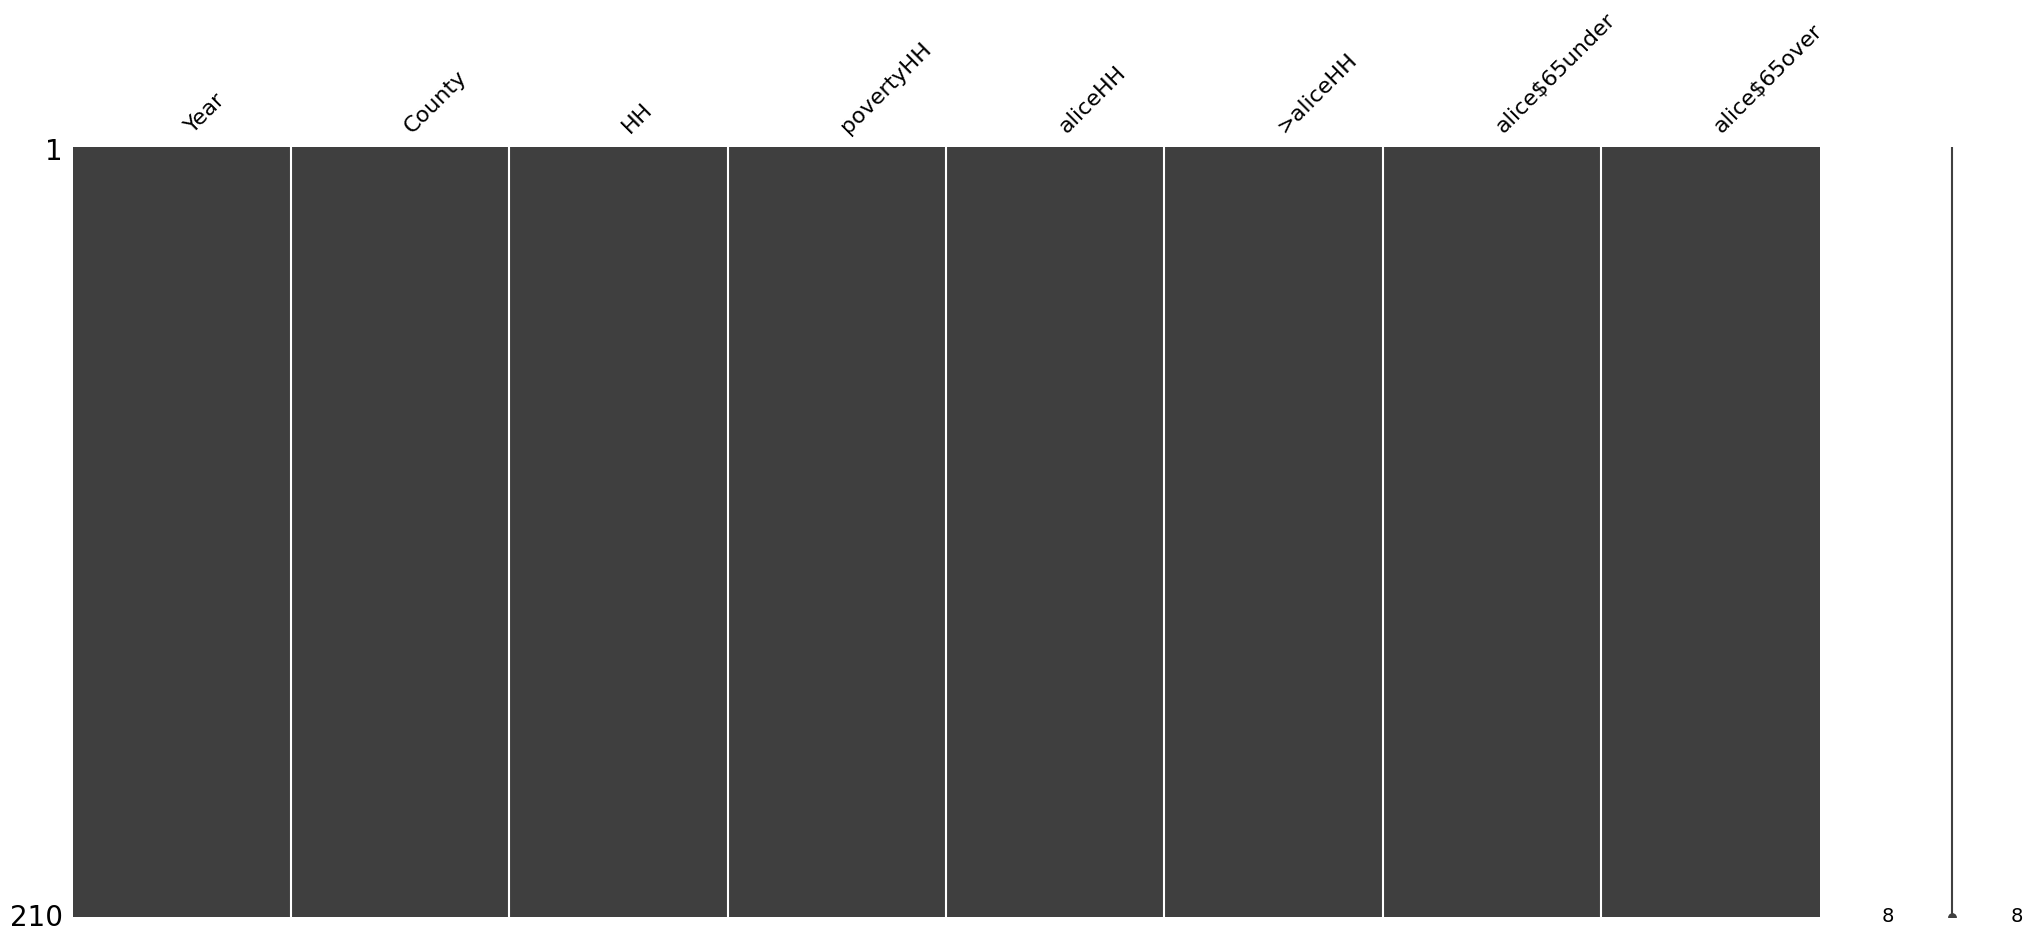

In [25]:
msno.matrix(alice)

In [26]:
alice.dtypes

,0
Year,int64
County,object
HH,int64
povertyHH,int64
aliceHH,int64
>aliceHH,int64
alice$65under,int64
alice$65over,int64


**Dataset check:** Kept only variables I'm interested in and renamed them to shorter names. Confirmed that numeric variables are integers.

#ACS Data
Data on population and income for every county in New Jersey. 1-year estimates except for 2020 (obtained from 5-year estimates). This is a zip file with individuals csv files for each year.

**Variables of Interest:** County, total population, total housing units, median income.

**Timeframe available:** 2010 through 2025.

**Areas in dataset:** Counties in New Jersey.

**Source:** [American Community Survey](https://www.census.gov/programs-surveys/acs/data.html)

In [27]:
! wget -q -O ACS_pop.zip https://github.com/carlavilla/DataManagement/raw/main/ACS_pop.zip
zip_ref = zipfile.ZipFile('ACS_pop.zip', 'r'); zip_ref.extractall(); zip_ref.close()
#https://raw.githubusercontent.com/carlavilla/DataManagement/main/ACS_pop.zip
with zipfile.ZipFile("ACS_pop.zip", 'r') as zip_ref:
    # Get a list of all file paths inside the ZIP so we can read them.
    pop_list = zip_ref.namelist()
    pop_list

['ACSDP1Y2025.DP05-Data.csv',
 'ACSDP1Y2025.DP05-Column-Metadata.csv',
 'ACSDP1Y2025.DP05-Table-Notes.txt',
 'ACSDP1Y2024.DP05-Data.csv',
 'ACSDP1Y2024.DP05-Column-Metadata.csv',
 'ACSDP1Y2024.DP05-Table-Notes.txt',
 'ACSDP1Y2023.DP05-Data.csv',
 'ACSDP1Y2023.DP05-Column-Metadata.csv',
 'ACSDP1Y2023.DP05-Table-Notes.txt',
 'ACSDP1Y2022.DP05-Data.csv',
 'ACSDP1Y2022.DP05-Column-Metadata.csv',
 'ACSDP1Y2022.DP05-Table-Notes.txt',
 'ACSDP1Y2021.DP05-Data.csv',
 'ACSDP1Y2021.DP05-Column-Metadata.csv',
 'ACSDP1Y2021.DP05-Table-Notes.txt',
 'ACSDP1Y2019.DP05-Data.csv',
 'ACSDP1Y2019.DP05-Column-Metadata.csv',
 'ACSDP1Y2019.DP05-Table-Notes.txt',
 'ACSDP1Y2018.DP05-Data.csv',
 'ACSDP1Y2018.DP05-Column-Metadata.csv',
 'ACSDP1Y2018.DP05-Table-Notes.txt',
 'ACSDP1Y2017.DP05-Data.csv',
 'ACSDP1Y2017.DP05-Column-Metadata.csv',
 'ACSDP1Y2017.DP05-Table-Notes.txt',
 'ACSDP1Y2016.DP05-Data.csv',
 'ACSDP1Y2016.DP05-Column-Metadata.csv',
 'ACSDP1Y2016.DP05-Table-Notes.txt',
 'ACSDP1Y2015.DP05-Data.csv'

In [29]:
acspop2010=pd.read_csv('ACSDP1Y2010.DP05-Data.csv')
acspop2010.head(3)

,GEO_ID,NAME,DP05_0001E,DP05_0001M,DP05_0001PE,DP05_0001PM,DP05_0002E,DP05_0002M,DP05_0002PE,DP05_0002PM,...,DP05_0079PM,DP05_0080E,DP05_0080M,DP05_0080PE,DP05_0080PM,DP05_0081E,DP05_0081M,DP05_0081PE,DP05_0081PM,Unnamed: 326
0,Geography,Geographic Area Name,Estimate!!SEX AND AGE!!Total population,Estimate Margin of Error!!SEX AND AGE!!Total p...,Percent!!SEX AND AGE!!Total population,Percent Margin of Error!!SEX AND AGE!!Total po...,Estimate!!SEX AND AGE!!Male,Estimate Margin of Error!!SEX AND AGE!!Male,Percent!!SEX AND AGE!!Male,Percent Margin of Error!!SEX AND AGE!!Male,...,Percent Margin of Error!!HISPANIC OR LATINO AN...,Estimate!!HISPANIC OR LATINO AND RACE!!Not His...,Estimate Margin of Error!!HISPANIC OR LATINO A...,Percent!!HISPANIC OR LATINO AND RACE!!Not Hisp...,Percent Margin of Error!!HISPANIC OR LATINO AN...,Estimate!!Total housing units,Estimate Margin of Error!!Total housing units,Percent!!Total housing units,Percent Margin of Error!!Total housing units,NaN
1,0500000US34001,"Atlantic County, New Jersey",274685,*****,274685,(X),132679,611,48.3,0.2,...,0.1,3115,1236,1.1,0.4,126723,861,(X),(X),NaN
2,0500000US34003,"Bergen County, New Jersey",906541,*****,906541,(X),436535,1088,48.2,0.1,...,0.1,10773,2346,1.2,0.3,352412,875,(X),(X),NaN


**Data check:** sets have two headers, counties have extra words in them than ALICE dataset, and too many columns to display easily.

In [7]:
acspop2010=pd.read_csv('ACSDP1Y2010.DP05-Data.csv') #read specific file
acspop2010= acspop2010[['NAME', 'DP05_0001E', 'DP05_0081E']] #keep only variables of interest (county, total population, total household units)
acspop2010['Year'] = 2010 #add year to this set so we can differentiate this values later
acspop10= acspop2010.drop([0]) #get rid of first index i.e. second header. Keeping first header because name is simpler
acspop10= acspop10.rename(columns={'DP05_0081E': 'H_units'}) #renaming this one now because variable name changes in later years; preventing merging headache later

acspop2012=pd.read_csv('ACSDP1Y2012.DP05-Data.csv')
acspop2012= acspop2012[['NAME', 'DP05_0001E', 'DP05_0081E']]
acspop2012['Year'] = 2012
acspop12= acspop2012.drop([0])
acspop12= acspop12.rename(columns={'DP05_0081E': 'H_units'})

acspop2014=pd.read_csv('ACSDP1Y2014.DP05-Data.csv')
acspop2014= acspop2014[['NAME', 'DP05_0001E', 'DP05_0081E']]
acspop2014['Year'] = 2014
acspop14= acspop2014.drop([0])
acspop14= acspop14.rename(columns={'DP05_0081E': 'H_units'})

acspop2016=pd.read_csv('ACSDP1Y2016.DP05-Data.csv')
acspop2016= acspop2016[['NAME', 'DP05_0001E', 'DP05_0081E']]
acspop2016['Year'] = 2016
acspop16= acspop2016.drop([0])
acspop16= acspop16.rename(columns={'DP05_0081E': 'H_units'})

acspop2018=pd.read_csv('ACSDP1Y2018.DP05-Data.csv')
acspop2018= acspop2018[['NAME', 'DP05_0001E', 'DP05_0086E']]
acspop2018['Year'] = 2018
acspop18= acspop2018.drop([0])
acspop18= acspop18.rename(columns={'DP05_0086E': 'H_units'})

acspop2019=pd.read_csv('ACSDP1Y2019.DP05-Data.csv')
acspop2019= acspop2019[['NAME', 'DP05_0001E', 'DP05_0086E']]
acspop2019['Year'] = 2019
acspop19= acspop2019.drop([0])
acspop19= acspop19.rename(columns={'DP05_0086E': 'H_units'})

acspop2021=pd.read_csv('ACSDP1Y2021.DP05-Data.csv')
acspop2021= acspop2021[['NAME', 'DP05_0001E', 'DP05_0086E']]
acspop2021['Year'] = 2021
acspop21= acspop2021.drop([0])
acspop21= acspop21.rename(columns={'DP05_0086E': 'H_units'})

acspop2022=pd.read_csv('ACSDP1Y2022.DP05-Data.csv')
acspop2022= acspop2022[['NAME', 'DP05_0001E', 'DP05_0088E']]
acspop2022['Year'] = 2022
acspop22= acspop2022.drop([0])
acspop22= acspop22.rename(columns={'DP05_0088E': 'H_units'})

acspop2023=pd.read_csv('ACSDP1Y2023.DP05-Data.csv')
acspop2023= acspop2023[['NAME', 'DP05_0001E', 'DP05_0091E']]
acspop2023['Year'] = 2023
acspop23= acspop2023.drop([0])
acspop23= acspop23.rename(columns={'DP05_0091E': 'H_units'})

acspop2024=pd.read_csv('ACSDP1Y2024.DP05-Data.csv')
acspop2024= acspop2024[['NAME', 'DP05_0001E', 'DP05_0105E']]
acspop2024['Year'] = 2024
acspop24= acspop2024.drop([0])
acspop24= acspop24.rename(columns={'DP05_0105E': 'H_units'})

In [8]:
acspop= pd.concat([acspop10, acspop12, acspop14, acspop16, acspop18, acspop19, acspop21, acspop22, acspop23, acspop24]) #combining all 10 years for all counties in one dataset
acspop.rename(columns={'NAME': 'County',
                       'DP05_0001E': "Totalpop"},
              inplace=True)
acspop['County'] = acspop['County'].str.replace(' County, New Jersey', '')
acspop= acspop.reset_index(drop=True)
acspop.head(3)

,County,Totalpop,H_units,Year
0,Atlantic,274685,126723,2010
1,Bergen,906541,352412,2010
2,Burlington,449149,175728,2010


In [30]:
acspop.dtypes

,0
County,object
Totalpop,object
H_units,object
Year,int64


In [31]:
acspop[['Totalpop']] = acspop[['Totalpop']].apply(pd.to_numeric) #changing numberic variables from object to int64. Suggested by Gemini.
acspop[['H_units']] = acspop[['H_units']].apply(pd.to_numeric)
acspop.dtypes

,0
County,object
Totalpop,int64
H_units,int64
Year,int64


<Axes: >

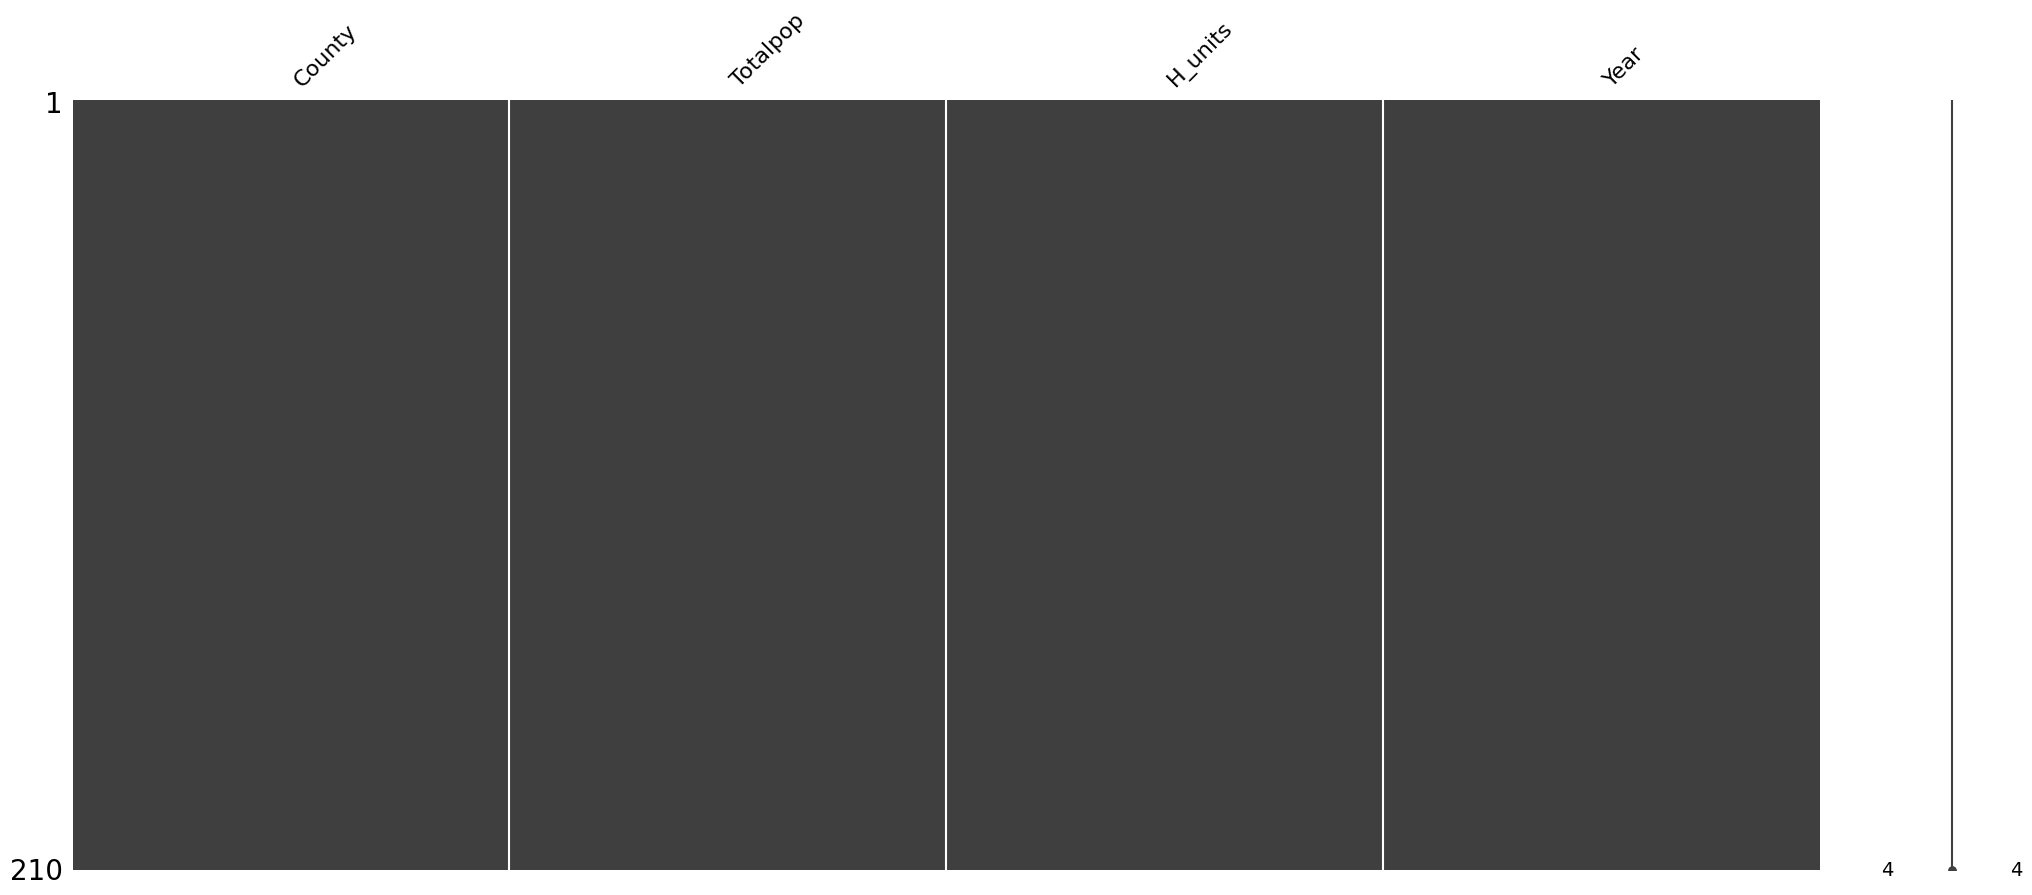

In [34]:
msno.matrix(acspop)

**Data check:** Population and household numbers were changed from objects to integers. Matrix shows no data values missing.

In [10]:
! wget -q -O ACS_income.zip https://github.com/carlavilla/DataManagement/raw/main/ACS_income.zip
zip_ref = zipfile.ZipFile('ACS_income.zip', 'r'); zip_ref.extractall(); zip_ref.close()
with zipfile.ZipFile("ACS_income.zip", 'r') as zip_ref:
    income_list = zip_ref.namelist()
    income_list

['ACSST1Y2025.S1901-Data.csv',
 'ACSST1Y2025.S1901-Column-Metadata.csv',
 'ACSST1Y2025.S1901-Table-Notes.txt',
 'ACSST1Y2024.S1901-Data.csv',
 'ACSST1Y2024.S1901-Column-Metadata.csv',
 'ACSST1Y2024.S1901-Table-Notes.txt',
 'ACSST1Y2023.S1901-Data.csv',
 'ACSST1Y2023.S1901-Column-Metadata.csv',
 'ACSST1Y2023.S1901-Table-Notes.txt',
 'ACSST1Y2022.S1901-Data.csv',
 'ACSST1Y2022.S1901-Column-Metadata.csv',
 'ACSST1Y2022.S1901-Table-Notes.txt',
 'ACSST1Y2021.S1901-Data.csv',
 'ACSST1Y2021.S1901-Column-Metadata.csv',
 'ACSST1Y2021.S1901-Table-Notes.txt',
 'ACSST1Y2019.S1901-Data.csv',
 'ACSST1Y2019.S1901-Column-Metadata.csv',
 'ACSST1Y2019.S1901-Table-Notes.txt',
 'ACSST1Y2018.S1901-Data.csv',
 'ACSST1Y2018.S1901-Column-Metadata.csv',
 'ACSST1Y2018.S1901-Table-Notes.txt',
 'ACSST1Y2017.S1901-Data.csv',
 'ACSST1Y2017.S1901-Column-Metadata.csv',
 'ACSST1Y2017.S1901-Table-Notes.txt',
 'ACSST1Y2016.S1901-Data.csv',
 'ACSST1Y2016.S1901-Column-Metadata.csv',
 'ACSST1Y2016.S1901-Table-Notes.txt',
 

In [11]:
acsinc2010=pd.read_csv('ACSST1Y2010.S1901-Data.csv')
acsinc2010= acsinc2010[['NAME', 'S1901_C01_012E']]
acsinc2010['Year'] = 2010
acsinc10= acsinc2010.drop([0])
acsinc10= acsinc10.rename(columns={'S1901_C01_012E': 'Median_income'})

acsinc2012=pd.read_csv('ACSST1Y2012.S1901-Data.csv')
acsinc2012= acsinc2012[['NAME', 'S1901_C01_012E']]
acsinc2012['Year'] = 2012
acsinc12= acsinc2012.drop([0])
acsinc12= acsinc12.rename(columns={'S1901_C01_012E': 'Median_income'})

acsinc2014=pd.read_csv('ACSST1Y2014.S1901-Data.csv')
acsinc2014= acsinc2014[['NAME', 'S1901_C01_012E']]
acsinc2014['Year'] = 2014
acsinc14= acsinc2014.drop([0])
acsinc14= acsinc14.rename(columns={'S1901_C01_012E': 'Median_income'})

acsinc2016=pd.read_csv('ACSST1Y2016.S1901-Data.csv')
acsinc2016= acsinc2016[['NAME', 'S1901_C01_012E']]
acsinc2016['Year'] = 2016
acsinc16= acsinc2016.drop([0])
acsinc16= acsinc16.rename(columns={'S1901_C01_012E': 'Median_income'})

acsinc2018=pd.read_csv('ACSST1Y2018.S1901-Data.csv')
acsinc2018= acsinc2018[['NAME', 'S1901_C01_012E']]
acsinc2018['Year'] = 2018
acsinc18= acsinc2018.drop([0])
acsinc18= acsinc18.rename(columns={'S1901_C01_012E': 'Median_income'})

acsinc2019=pd.read_csv('ACSST1Y2019.S1901-Data.csv')
acsinc2019= acsinc2019[['NAME', 'S1901_C01_012E']]
acsinc2019['Year'] = 2019
acsinc19= acsinc2019.drop([0])
acsinc19= acsinc19.rename(columns={'S1901_C01_012E': 'Median_income'})

acsinc2021=pd.read_csv('ACSST1Y2021.S1901-Data.csv')
acsinc2021= acsinc2021[['NAME', 'S1901_C01_012E']]
acsinc2021['Year'] = 2021
acsinc21= acsinc2021.drop([0])
acsinc21= acsinc21.rename(columns={'S1901_C01_012E': 'Median_income'})

acsinc2022=pd.read_csv('ACSST1Y2022.S1901-Data.csv')
acsinc2022= acsinc2022[['NAME', 'S1901_C01_012E']]
acsinc2022['Year'] = 2022
acsinc22= acsinc2022.drop([0])
acsinc22= acsinc22.rename(columns={'S1901_C01_012E': 'Median_income'})

acsinc2023=pd.read_csv('ACSST1Y2023.S1901-Data.csv')
acsinc2023= acsinc2023[['NAME', 'S1901_C01_012E']]
acsinc2023['Year'] = 2023
acsinc23= acsinc2023.drop([0])
acsinc23= acsinc23.rename(columns={'S1901_C01_012E': 'Median_income'})

acsinc2024=pd.read_csv('ACSST1Y2024.S1901-Data.csv')
acsinc2024= acsinc2024[['NAME', 'S1901_C01_012E']]
acsinc2024['Year'] = 2024
acsinc24= acsinc2024.drop([0])
acsinc24= acsinc24.rename(columns={'S1901_C01_012E': 'Median_income'})

In [12]:
acsinc= pd.concat([acsinc10, acsinc12, acsinc14, acsinc16, acsinc18, acsinc19, acsinc21, acsinc22, acsinc23, acsinc24])
acsinc.rename(columns={'NAME': 'County'},
              inplace=True)
acsinc['County'] = acsinc['County'].str.replace(' County, New Jersey', '')
acsinc= acsinc.reset_index(drop=True)
acsinc.head(3)

,County,Median_income,Year
0,Atlantic,52571,2010
1,Bergen,77389,2010
2,Burlington,74329,2010


In [35]:
acsinc.dtypes

,0
County,object
Median_income,object
Year,int64


In [36]:
acsinc[['Median_income']] = acsinc[['Median_income']].apply(pd.to_numeric) #changing numberic variables from object to int64. Suggested by Gemini.
acsinc.dtypes

,0
County,object
Median_income,int64
Year,int64


<Axes: >

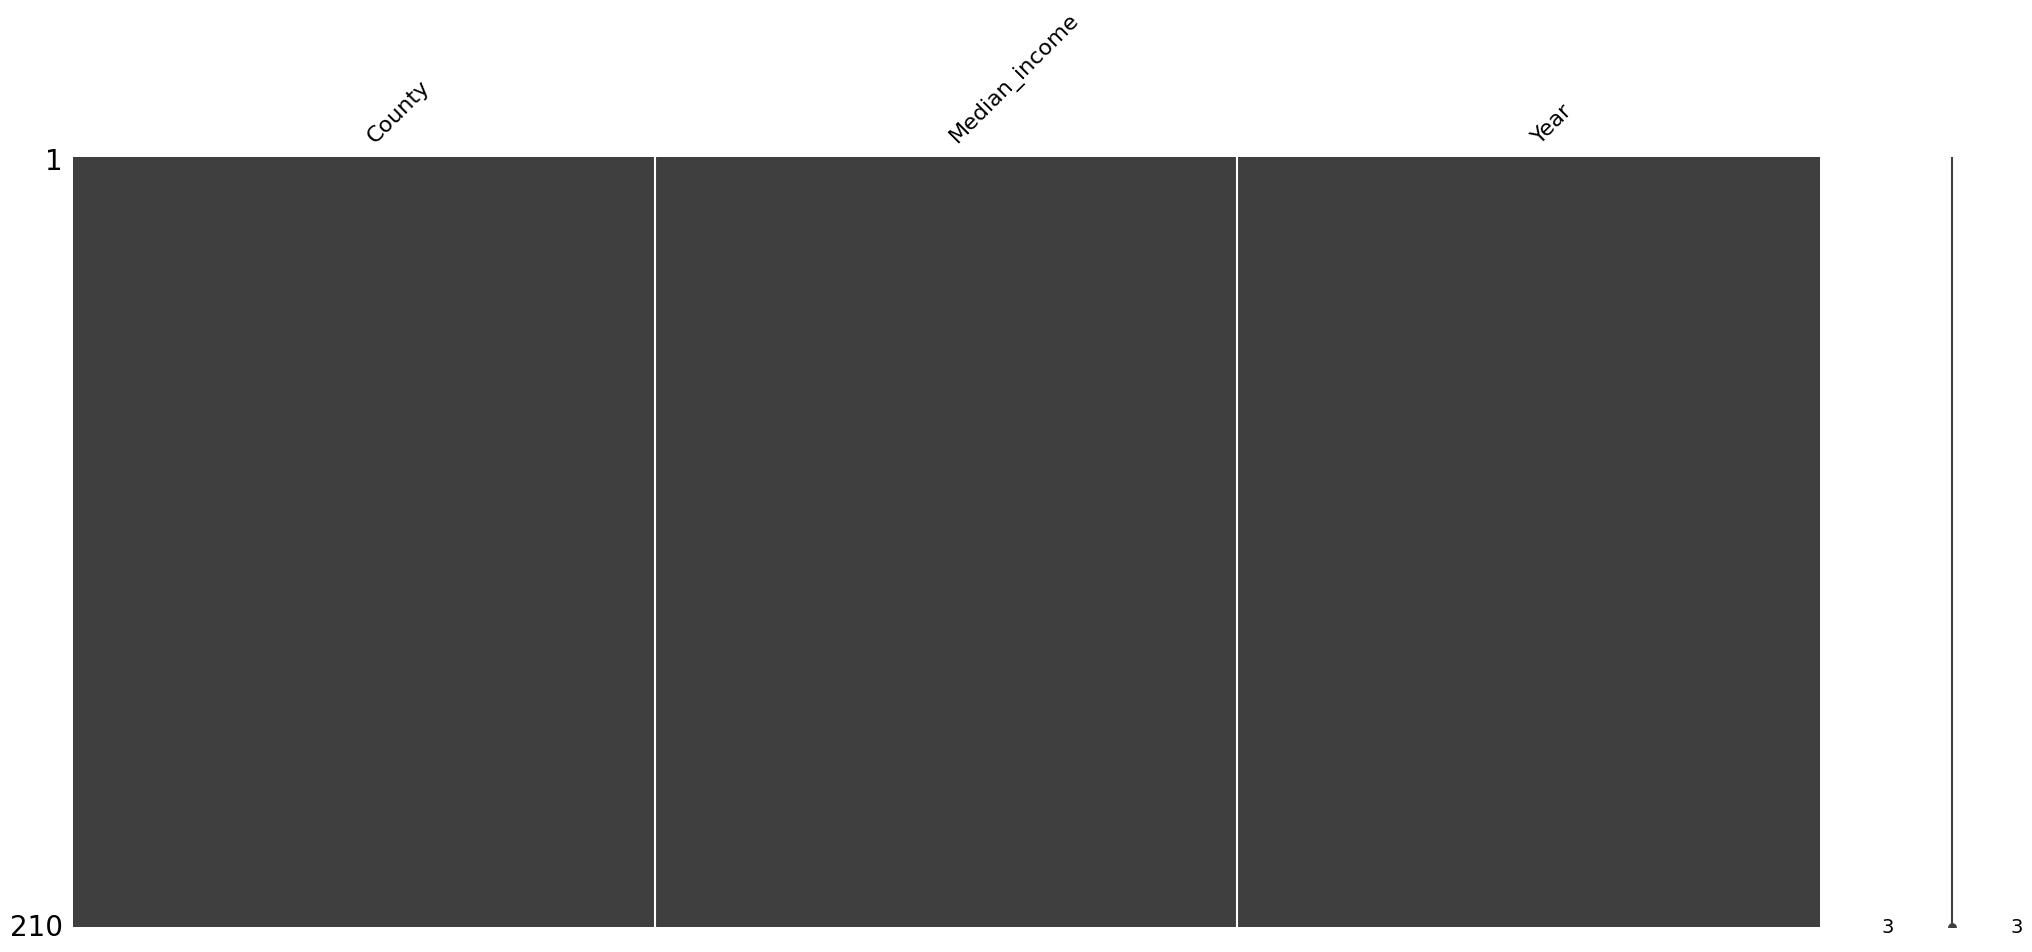

In [37]:
msno.matrix(acsinc)

**Data check:** Changed median income from object to integer. Matrix shows no values missing.

In [38]:
acs_popinc= pd.merge(acspop, acsinc, how="outer", on=['County', 'Year'], indicator=True)
acs_popinc.head(3)

,County,Totalpop,H_units,Year,Median_income,_merge
0,Atlantic,274685,126723,2010,52571,both
1,Atlantic,275422,127361,2012,51191,both
2,Atlantic,275209,127386,2014,55313,both


In [39]:
acs_popinc['_merge'].value_counts()

,count
_merge,
both,210
left_only,0
right_only,0


In [40]:
acs_popinc = acs_popinc.drop(columns=["_merge"])
acs_popinc.head(3)

,County,Totalpop,H_units,Year,Median_income
0,Atlantic,274685,126723,2010,52571
1,Atlantic,275422,127361,2012,51191
2,Atlantic,275209,127386,2014,55313


In [41]:
acs_popinc.dtypes

,0
County,object
Totalpop,int64
H_units,int64
Year,int64
Median_income,int64


**Dataset check:** Merged ACS data to have total population, household units, and median income all in one place. Merge check shows no values left out. Additionally, all numeric values are now integers and county name matches that of ALICE dataset for merge later. Since ALICE data is only available for specific years, this data set includes the same years to match.

#Zillow Data
Zillow home value index (ZHVI) and observed rent index (ZORI) for the 35th to 65th percentile range for homes in each county.

**Variables of interest:** end-of-year or average home value per year, end-of-year or average rent per year.

**Timeframe available:** monthly from 2000 through September 2026.

**Areas in dataset:** Counties in all of USA.

**Source:** [Zillow Housing Data](https://www.zillow.com/research/data/)

In [48]:
! wget -q -O county_zhvi_homevalue.csv https://raw.githubusercontent.com/carlavilla/DataManagement/main/county_zhvi_homevalue.csv
homeval=pd.read_csv('county_zhvi_homevalue.csv')
homeval.dtypes

,0
RegionID,int64
SizeRank,int64
RegionName,object
RegionType,object
StateName,object
...,...
2026-05-31,float64
2026-06-30,float64
2026-07-31,float64
2026-08-31,float64


In [49]:
homeval.head(3)

,RegionID,SizeRank,RegionName,RegionType,StateName,State,Metro,StateCodeFIPS,MunicipalCodeFIPS,2000-01-31,...,2025-12-31,2026-01-31,2026-02-28,2026-03-31,2026-04-30,2026-05-31,2026-06-30,2026-07-31,2026-08-31,2026-09-30
0,3101,0,Los Angeles County,county,CA,CA,"Los Angeles-Long Beach-Anaheim, CA",6,37,209582.581236,...,877349.227920,879025.499041,879001.098887,877195.250555,874505.933403,872147.441903,870027.097408,869585.950536,870371.239695,871674.448215
1,139,1,Cook County,county,IL,IL,"Chicago-Naperville-Elgin, IL-IN-WI",17,31,151146.336479,...,325492.652896,326946.311124,328660.167000,330259.972515,331587.056183,332541.397030,333774.498218,335654.082618,338036.282057,340257.851965
2,1090,2,Harris County,county,TX,TX,"Houston-The Woodlands-Sugar Land, TX",48,201,112253.637735,...,281475.452233,281328.527340,280995.589028,280392.118313,279683.563430,278703.261582,277655.415453,276903.574179,276625.749653,276524.384876


**Data check:** dataset contains too much irrelevant information. We'll narrow it down to just NJ (using "State") and years of interest first.

In [93]:
zhviNJ= homeval[homeval['State']=='NJ'] #keeping only where state is NJ
zhviNJ.info() #checking there's only 21 counties

<class 'pandas.core.frame.DataFrame'>
Index: 21 entries, 54 to 830
Columns: 330 entries, RegionID to 2026-09-30
dtypes: float64(321), int64(4), object(5)
memory usage: 54.3+ KB


In [94]:
zhviNJ.head(3)

,RegionID,SizeRank,RegionName,RegionType,StateName,State,Metro,StateCodeFIPS,MunicipalCodeFIPS,2000-01-31,...,2025-12-31,2026-01-31,2026-02-28,2026-03-31,2026-04-30,2026-05-31,2026-06-30,2026-07-31,2026-08-31,2026-09-30
54,874,54,Bergen County,county,NJ,NJ,"New York-Newark-Jersey City, NY-NJ-PA",34,3,237614.630828,...,742591.693202,746869.504424,751757.593334,756720.479614,760051.622447,763030.997779,766018.430554,770981.359291,776347.823666,780356.676082
69,2802,69,Middlesex County,county,NJ,NJ,"New York-Newark-Jersey City, NY-NJ-PA",34,23,178215.449867,...,569339.429502,571884.249622,574922.384248,577816.720838,578436.881376,577734.013965,576914.145697,577657.906598,579461.628135,579851.940173
71,504,71,Essex County,county,NJ,NJ,"New York-Newark-Jersey City, NY-NJ-PA",34,13,190095.864814,...,643252.145140,645765.989252,647716.563822,649844.739257,650594.332821,651367.119371,652221.261306,654114.808020,656697.831198,658593.091203


In [95]:
target_years = ['2010', '2012', '2014', '2016', '2018', '2019', '2021', '2022', '2023', '2024']
zhvi_years = []
for i in zhviNJ.columns:
    if any(yr in i for yr in target_years):
        zhvi_years.append(i)
zhvi_years

['2010-01-31',
 '2010-02-28',
 '2010-03-31',
 '2010-04-30',
 '2010-05-31',
 '2010-06-30',
 '2010-07-31',
 '2010-08-31',
 '2010-09-30',
 '2010-10-31',
 '2010-11-30',
 '2010-12-31',
 '2012-01-31',
 '2012-02-29',
 '2012-03-31',
 '2012-04-30',
 '2012-05-31',
 '2012-06-30',
 '2012-07-31',
 '2012-08-31',
 '2012-09-30',
 '2012-10-31',
 '2012-11-30',
 '2012-12-31',
 '2014-01-31',
 '2014-02-28',
 '2014-03-31',
 '2014-04-30',
 '2014-05-31',
 '2014-06-30',
 '2014-07-31',
 '2014-08-31',
 '2014-09-30',
 '2014-10-31',
 '2014-11-30',
 '2014-12-31',
 '2016-01-31',
 '2016-02-29',
 '2016-03-31',
 '2016-04-30',
 '2016-05-31',
 '2016-06-30',
 '2016-07-31',
 '2016-08-31',
 '2016-09-30',
 '2016-10-31',
 '2016-11-30',
 '2016-12-31',
 '2018-01-31',
 '2018-02-28',
 '2018-03-31',
 '2018-04-30',
 '2018-05-31',
 '2018-06-30',
 '2018-07-31',
 '2018-08-31',
 '2018-09-30',
 '2018-10-31',
 '2018-11-30',
 '2018-12-31',
 '2019-01-31',
 '2019-02-28',
 '2019-03-31',
 '2019-04-30',
 '2019-05-31',
 '2019-06-30',
 '2019-07-

In [99]:
#Done with Gemini
# 1. Filter the columns that contain any of our target years, keeping 'RegionName'
columns_to_melt = ['RegionName'] + [col for col in zhviNJ.columns if any(year in col for year in target_years)]

# 2. Melt (stack) the dataset using RegionName as the ID
zhvi_long_all = pd.melt(
    zhviNJ[columns_to_melt],
    id_vars=['RegionName'],
    var_name='Date',
    value_name='HomeValue'
)

# 3. Convert 'Date' to datetime for chronological plotting
zhvi_long_all['Date'] = pd.to_datetime(zhvi_long_all['Date'])

# 4. Create the clean 'County' column for the legend
zhvi_long_all['County'] = zhvi_long_all['RegionName'].str.replace(' County', '')

# Display the top of our newly reshaped dataset
zhvi_long_all.head()

,RegionName,Date,HomeValue,County
0,Bergen County,2010-01-31,426977.848488,Bergen
1,Middlesex County,2010-01-31,322001.605191,Middlesex
2,Essex County,2010-01-31,345641.178137,Essex
3,Hudson County,2010-01-31,328202.337875,Hudson
4,Monmouth County,2010-01-31,372363.795201,Monmouth


<Axes: xlabel='Date', ylabel='HomeValue'>

Text(0.5, 1.0, 'Zillow Home Value Index (ZHVI) Trends by NJ County')

Text(0.5, 0, 'Year')

Text(0, 0.5, 'Home Value ($)')

<Figure size 640x480 with 0 Axes>

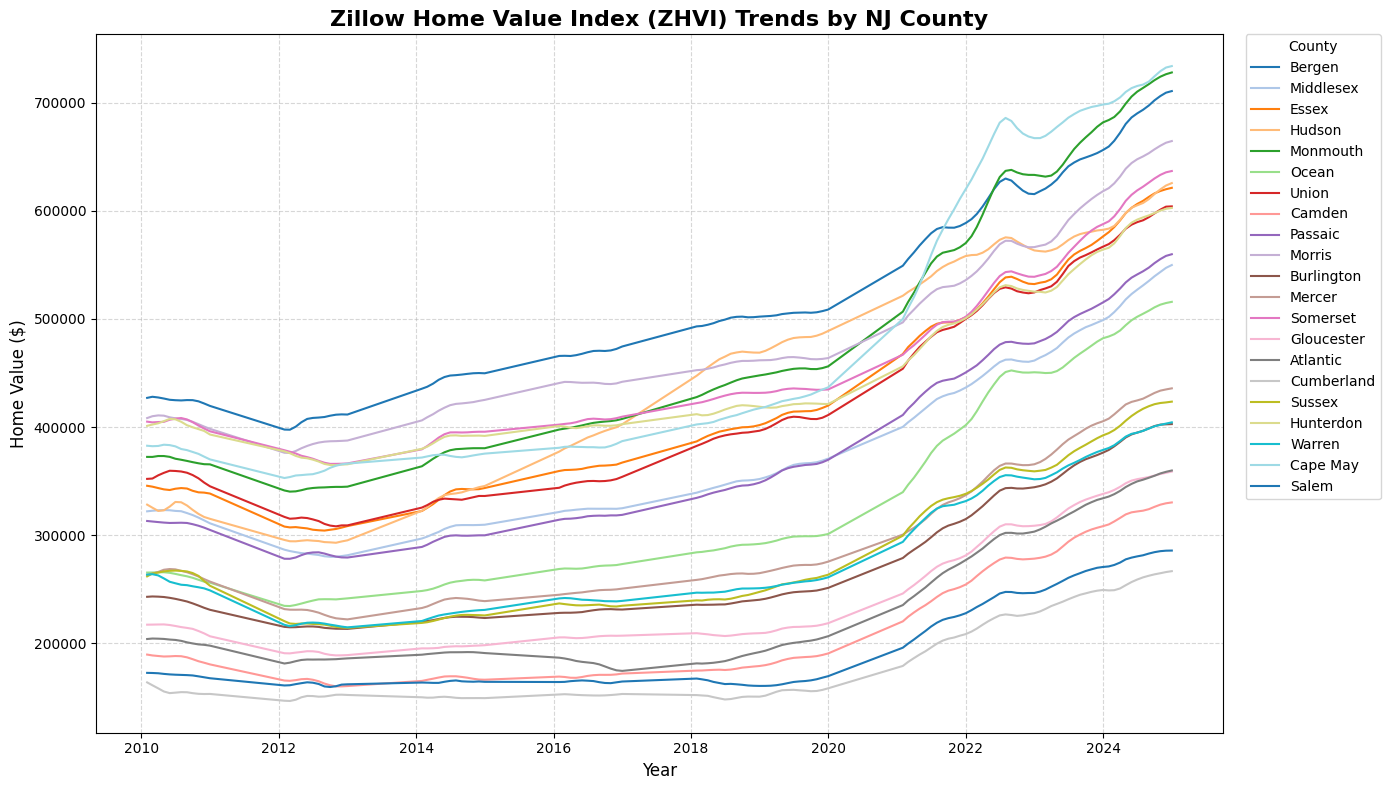

In [100]:
# Clear previous figures and set a clean style
plt.clf()
fig, ax = plt.subplots(figsize=(14, 8))

# Create the chronological line plot
sns.lineplot(
    data=zhvi_long_all,
    x='Date',
    y='HomeValue',
    hue='County',
    palette='tab20',
    linewidth=1.5,
    ax=ax
)

# Enhance readability and formatting
ax.set_title('Zillow Home Value Index (ZHVI) Trends by NJ County', fontsize=16, fontweight='bold')
ax.set_xlabel('Year', fontsize=12)
ax.set_ylabel('Home Value ($)', fontsize=12)
ax.grid(True, linestyle='--', alpha=0.5)
ax.legend(title='County', bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0.)

plt.tight_layout()
plt.show()

In [112]:
#Created with Gemini
# Extract the year from the 'Date' column
zhvi_long_all['Year'] = zhvi_long_all['Date'].dt.year

# Group by County and Year to compute the average annual home value
annual_zhvi_avg = zhvi_long_all.groupby(['County', 'Year'])['HomeValue'].mean().reset_index()
annual_zhvi_avg = annual_zhvi_avg.rename(columns={'HomeValue': 'Avg_ZHVI'})

# Display the resulting DataFrame
annual_zhvi_avg.head(15)

,County,Year,Avg_ZHVI
0,Atlantic,2010,201701.717901
1,Atlantic,2012,184358.094629
2,Atlantic,2014,191031.523758
3,Atlantic,2016,180986.641088
4,Atlantic,2018,185270.105903
5,Atlantic,2019,200181.537126
6,Atlantic,2021,257364.803407
7,Atlantic,2022,296036.864825
8,Atlantic,2023,320390.745680
9,Atlantic,2024,349223.549407


In [113]:
homevalNJ= annual_zhvi_avg.copy()
homevalNJ.dtypes

,0
County,object
Year,int32
Avg_ZHVI,float64


**Data check:** After melting the target years, I plotted the trends for each county to see if the home values consistently increase month to month. The graph shows that prices increase overall, but not consistently month to month for every county. Thus, I decided to use the average home value for each target year. Also confirmed that year and avg_zhvi are numeric.

In [106]:
! wget -q -O county_zori_rent.csv https://raw.githubusercontent.com/carlavilla/DataManagement/main/county_zori_rent.csv
rent=pd.read_csv('county_zori_rent.csv')
rent.dtypes

,0
RegionID,int64
SizeRank,int64
RegionName,object
RegionType,object
StateName,object
...,...
2026-05-31,float64
2026-06-30,float64
2026-07-31,float64
2026-08-31,float64


In [107]:
rent.head(3)

,RegionID,SizeRank,RegionName,RegionType,StateName,State,Metro,StateCodeFIPS,MunicipalCodeFIPS,2015-01-31,...,2025-12-31,2026-01-31,2026-02-28,2026-03-31,2026-04-30,2026-05-31,2026-06-30,2026-07-31,2026-08-31,2026-09-30
0,3101,0,Los Angeles County,county,CA,CA,"Los Angeles-Long Beach-Anaheim, CA",6,37,1685.050595,...,2755.646300,2758.526228,2764.684687,2776.787135,2784.763707,2792.919997,2797.195468,2797.764958,2801.043906,2806.073007
1,139,1,Cook County,county,IL,IL,"Chicago-Naperville-Elgin, IL-IN-WI",17,31,1389.605638,...,2108.340623,2122.851289,2142.993099,2168.673882,2190.298565,2211.395260,2228.722934,2237.459838,2234.504365,2227.715884
2,1090,2,Harris County,county,TX,TX,"Houston-The Woodlands-Sugar Land, TX",48,201,1167.700090,...,1567.008256,1566.079550,1564.196866,1566.014578,1568.898262,1575.401121,1579.254701,1581.341233,1580.997258,1582.680823


In [114]:
zoriNJ= rent[rent['State']=='NJ'] #keeping only where state is NJ
zoriNJ.info() #checking there's only 21 counties

<class 'pandas.core.frame.DataFrame'>
Index: 21 entries, 54 to 822
Columns: 150 entries, RegionID to 2026-09-30
dtypes: float64(141), int64(4), object(5)
memory usage: 24.8+ KB
